In [1]:
from pathlib import Path
import re, textwrap, time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
import xgboost as xgb
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 200)

DATA_DIR  = Path("./data")
FIG_DIR   = Path("./outputs/figures")
CACHE_DIR = Path("./outputs/cache")     # the OEWS spreadsheet is slow to read, so it is cached after the first run
QUICK_RUN = False                       # True = skip robustness checks
FIG_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def find_file(pattern):
    hits = sorted(p for p in DATA_DIR.rglob(pattern) if not p.name.startswith(("~$", ".")) and "Metadata" not in p.name)
    if not hits:
        raise FileNotFoundError(f"No file matching {pattern} in {DATA_DIR.resolve()}")
    return hits[-1]

ONET_TEXT     = find_file("Skills.txt").parent          # O*NET 30.2 text folder
OEWS_FILE     = find_file("all_data_M_2025*.xlsx")
AREA_DEF_FILE = find_file("area_definitions*.xlsx")
RENT_FILE     = find_file("*B25064*-Data.csv")
BEA_FILES     = sorted(set(DATA_DIR.rglob("*RPP*.csv")) | set(DATA_DIR.rglob("*IRPD*.csv")),   # MARPP (metros), SAIRPD (states)
                       key=lambda p: (0 if "RPP" in p.name.upper() else 1, p.name))
for k, v in [("O*NET", ONET_TEXT), ("OEWS", OEWS_FILE), ("Area definitions", AREA_DEF_FILE), ("ACS rents", RENT_FILE),
             ("BEA prices", ", ".join(f.name for f in BEA_FILES))]:
    print(f"{k:<18} {v}")

# ── Primary specification ──
PRIMARY = dict(
    ONET_SCALES=("LV", "IM"),       # O*NET level and importance ratings as separate measures
    CORR_THRESHOLD=0.80,            # combine measures while average |Spearman| >= this
    OUTCOME="hourly",               # "hourly" or "annual" median wages
    EMPLOYMENT_WEIGHTS=False,       # weight occupations by national employment
    EXCLUDE_TERRITORIES=True,
    LARGE_MIN=500_000,              # large metros: at least this many jobs (OEWS employment)
    SMALL_MAX=100_000,              # small metros: fewer than this many jobs
    CONTRAST=("Large metros", "Nonmetro (rural)"),
)
# Robustness specifications
SPECS = {
    "Primary specification":            {},
    "Level ratings only":               {"ONET_SCALES": ("LV",)},
    "Importance ratings only":          {"ONET_SCALES": ("IM",)},
    "Weighted by employment":           {"EMPLOYMENT_WEIGHTS": True},
    "Annual instead of hourly wages":   {"OUTCOME": "annual"},
    "Larger skill groups (corr >= 0.70)":  {"CORR_THRESHOLD": 0.70},
    "Smaller skill groups (corr >= 0.90)": {"CORR_THRESHOLD": 0.90},
    "Large metros >= 1M jobs":          {"LARGE_MIN": 1_000_000},
    "Large vs. small metros":           {"CONTRAST": ("Large metros", "Small metros")},
    "Including U.S. territories":       {"EXCLUDE_TERRITORIES": False},
}

# ── Other settings ──
RPP_YEAR          = 2024          # latest BEA price year <= this
MIN_OCC_PER_AREA  = 50            # drop areas reporting fewer occupations
MIN_AREAS_PER_OCC = 5             # market-type comparisons: occupation reported in >= this many areas of each type
MAX_FEAT_MISS     = 0.20          # drop O*NET measures missing for more than this share of occupations
MAX_ROW_MISS      = 0.50          # drop occupations missing more than this share of measures
N_FOLDS           = 5
CORE_REPEATS      = 5             # repetitions of the core test
N_BOOT_COMPARE    = 1000          # bootstrap draws for the market type comparisons
N_BOOT_CASE       = 20            # bootstrap refits for Seattle vs. Yakima
FDR               = 0.10          # Benjamini-Hochberg false discovery rate
RUN_ROBUSTNESS    = True
ROBUST_AREA_SAMPLE = 150          # robustness runs compute premium rank correlations on this many random areas
CASE_AREAS        = ("Seattle", "Yakima")
RANDOM_STATE      = 42
N_BINS            = 10
if QUICK_RUN:
    CORE_REPEATS, N_BOOT_COMPARE, N_BOOT_CASE, RUN_ROBUSTNESS = 2, 200, 5, False

NATIONAL_PARAMS = dict(n_estimators=600, max_depth=7, learning_rate=0.01, subsample=0.7, colsample_bytree=0.6,
                       min_child_weight=1, random_state=RANDOM_STATE)
POOLED_PARAMS   = dict(n_estimators=500, max_depth=7, learning_rate=0.05, subsample=0.7, colsample_bytree=0.6,
                       min_child_weight=5, random_state=RANDOM_STATE)
CASE_PARAMS     = dict(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.6,
                       min_child_weight=1, random_state=RANDOM_STATE)

# Names for skill groups, named by the group's central measure without its scale.
# Names never affect results. groups without a name here are labelled "<central measure> group".
GROUP_LABELS = {
    "SK_Active Learning": "General cognitive skills & credentials",
    "SK_Critical Thinking": "General cognitive skills & credentials",
    "AB_Static Strength": "Physical strength & stamina",
    "SK_Troubleshooting": "Equipment operation & repair",
    "SK_Equipment Maintenance": "Equipment operation & repair",
    "AB_Peripheral Vision": "Vehicle operation & spatial perception",
    "AB_Reaction Time": "Psychomotor speed & coordination",
    "AB_Manual Dexterity": "Fine motor dexterity",
    "AB_Arm-Hand Steadiness": "Fine motor dexterity",
    "AB_Oral Expression": "Oral communication",
    "AB_Speech Clarity": "Speech clarity & recognition",
    "SK_Persuasion": "Persuasion, negotiation & service",
    "SK_Negotiation": "Persuasion, negotiation & service",
    "SK_Service Orientation": "Service orientation",
    "WA_Analyzing Data or Information": "Information processing & analysis",
    "WA_Processing Information": "Information processing & analysis",
    "WA_Guiding, Directing, and Motivating Subordinates": "Supervising & coordinating people",
    "AB_Mathematical Reasoning": "Quantitative skills",
    "AB_Category Flexibility": "Information ordering & categorization",
    "AB_Originality": "Creativity & idea generation",
    "AB_Auditory Attention": "Hearing",
    "AB_Hearing Sensitivity": "Hearing",
    "KN_Psychology": "Psychology & counseling knowledge",
    "KN_Sociology and Anthropology": "Psychology & social science knowledge",
    "KN_Computers and Electronics": "Computer knowledge & use",
    "KN_Design": "Design & engineering knowledge",
    "KN_Engineering and Technology": "Design & engineering knowledge",
    "KN_Philosophy and Theology": "Philosophy, theology & social science",
    "SK_Learning Strategies": "Instructing & teaching",
    "SK_Management of Personnel Resources": "Managing people & time",
    "SK_Management of Financial Resources": "Managing financial & material resources",
    "WA_Coaching and Developing Others": "Coaching & training others",
    "WA_Developing Objectives and Strategies": "Strategy & advising",
    "WA_Organizing, Planning, and Prioritizing Work": "Planning & scheduling work",
    "WC_Exposed to Hazardous Equipment": "Hazard exposure",
    "WC_Exposed to Very Hot or Cold Temperatures": "Temperature extremes & exposed settings",
    "WC_Spend Time Standing": "Work posture (standing vs. sitting)",
    "WC_Wear Common Protective or Safety Equipment such as Safety Shoes, Glasses, Gloves, Hearing Protection, Hard Hats, or Life Jackets": "Protective equipment & hazardous conditions",
    "WC_Determine Tasks, Priorities and Goals": "Work autonomy",
    "WC_Exposed to High Places": "Heights & climbing",
    "WC_Frequency of Decision Making": "Decision frequency & impact",
    "WC_Outdoors, Exposed to All Weather Conditions": "Outdoor work",
    "WC_Spend Time Keeping or Regaining Balance": "Balancing, kneeling & crouching",
}
T0 = time.time()

O*NET              data\db_30_2_text
OEWS               data\all_data_M_2025.xlsx
Area definitions   data\area_definitions_m2025.xlsx
ACS rents          data\ACSDT5Y2023.B25064-Data.csv
BEA prices         MARPP_MSA_2008_2024.csv, SAIRPD_STATE_2008_2024.csv


## 1. OEWS wages and market characteristics

Cross-industry estimates for the US, metropolitan areas, and nonmetropolitan areas. Each area's market
characteristics come from total employment, whether it is nonmetropolitan, and its occupational mix
(employment shares of the 22 major occupation groups).

In [2]:
AREA_TYPE_MAP = {"1": "national", "2": "state", "3": "territory", "4": "msa", "6": "nonmetro"}
TERRITORIES = {"PR", "GU", "VI", "AS", "MP"}

def _num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")

cache = CACHE_DIR / f"oews_raw_{OEWS_FILE.stem}_{OEWS_FILE.stat().st_size}.pkl"
if cache.exists():
    raw = pd.read_pickle(cache)
else:
    raw = pd.read_excel(OEWS_FILE, dtype=str)
    raw.columns = raw.columns.str.upper().str.strip()
    raw.to_pickle(cache)

r_ = raw.copy()
if "I_GROUP" in r_.columns:
    r_ = r_[r_["I_GROUP"].astype(str).str.lower().str.strip().eq("cross-industry")]
if "OWN_CODE" in r_.columns and r_.duplicated(["AREA", "OCC_CODE"]).any():
    r_ = r_[r_["OWN_CODE"].astype(str).str.strip().eq("1235")]
a_raw, h_raw = r_["A_MEDIAN"].astype(str).str.strip(), r_["H_MEDIAN"].astype(str).str.strip()
oe = pd.DataFrame({
    "area": r_["AREA"].astype(str).str.strip(), "area_title": r_["AREA_TITLE"].astype(str),
    "area_type": r_["AREA_TYPE"].astype(str).str.strip().map(AREA_TYPE_MAP).fillna("other"),
    "prim_state": r_["PRIM_STATE"].astype(str).str.strip().str.upper(),
    "soc": r_["OCC_CODE"].astype(str).str.strip(), "occ_title": r_["OCC_TITLE"].astype(str),
    "o_group": r_["O_GROUP"].astype(str).str.lower().str.strip(),
    "tot_emp": _num(r_["TOT_EMP"]), "a_median": _num(a_raw), "h_median": _num(h_raw),
    "topcoded": a_raw.eq("#") | h_raw.eq("#"),
})
oe["area_key"] = oe["area"].str.lstrip("0")
det = oe[oe["o_group"].eq("detailed")].copy()
nat = det[det["area_type"].eq("national")].drop_duplicates("soc").set_index("soc")
local = oe[oe["area_type"].isin(["msa", "nonmetro"])]

def outcome(df, kind):
    # Median wage: annual-only occupations converted at 2,080 hours (and the reverse for annual wages)
    if kind == "hourly":
        return df["h_median"].where(df["h_median"].notna(), df["a_median"] / 2080)
    return df["a_median"].where(df["a_median"].notna(), df["h_median"] * 2080)

# Market characteristics
area_info = local.groupby("area_key").agg(area_title=("area_title", "first"), area_type=("area_type", "first"),
                                          prim_state=("prim_state", "first"))
emp_total = local[local["soc"].eq("00-0000")].groupby("area_key")["tot_emp"].first()
maj = local[local["o_group"].eq("major")]
maj_emp = maj.pivot_table(index="area_key", columns="soc", values="tot_emp", aggfunc="sum")
area_emp = (emp_total.reindex(area_info.index)
            .fillna(maj_emp.sum(axis=1, min_count=1).reindex(area_info.index))
            .fillna(det[det["area_type"].isin(["msa", "nonmetro"])].groupby("area_key")["tot_emp"].sum()))
area_info["emp"] = area_emp
M0 = pd.DataFrame(index=area_info.index)
M0["mkt_log_emp"] = np.log(area_emp.clip(lower=1))
M0["mkt_nonmetro"] = area_info["area_type"].eq("nonmetro").astype(float)
for c in maj_emp.columns:
    M0[f"mkt_occ_{c[:2]}"] = maj_emp[c].reindex(M0.index) / area_emp
print(f"Areas: {area_info['area_type'].value_counts().to_dict()}; market characteristics: {M0.shape[1]}")

Areas: {'msa': 393, 'nonmetro': 137}; market characteristics: 24


## 2. O\*NET measures and the OEWS match

Both level and the importance scale are used as separate measures for skills, knowledge, and work activities. Ratings O\*NET recommends suppressing are treated as missing, and
level ratings flagged "not relevant" are set to zero.

In [3]:
ONET_FILES = {"SK": "Skills.txt", "KN": "Knowledge.txt", "AB": "Abilities.txt", "WA": "Work Activities.txt"}
KIND = {"SK": "skill", "KN": "knowledge", "AB": "ability", "WA": "work activity", "WC": "work context"}
RENAME = {"O*NET-SOC Code": "onet_soc", "Element Name": "element", "Scale ID": "scale", "Data Value": "value",
          "Recommend Suppress": "suppress", "Not Relevant": "not_relevant", "Job Zone": "job_zone"}

def read_onet(name):
    d = pd.read_csv(ONET_TEXT / name, sep="\t", dtype=str)
    return d.rename(columns={c: RENAME.get(c.strip(), c) for c in d.columns})

def clean(d, zero_not_relevant):
    d = d.copy()
    d["v"] = pd.to_numeric(d["value"], errors="coerce")
    if "suppress" in d.columns:
        d.loc[d["suppress"].astype(str).str.upper().eq("Y"), "v"] = np.nan
    if zero_not_relevant and "not_relevant" in d.columns:
        d.loc[d["not_relevant"].astype(str).str.upper().eq("Y"), "v"] = 0.0
    return d

onet_raw = {p: read_onet(f) for p, f in ONET_FILES.items()}
wc_raw = read_onet("Work Context.txt")
wc_raw = clean(wc_raw[wc_raw["scale"].isin(["CX", "CT"])], zero_not_relevant=False)
jz_raw = read_onet("Job Zones.txt")
safe = lambda c: c.replace("[", "(").replace("]", ")").replace("<", "lt")   # XGBoost-safe names

def onet_by_soc(scales):
    frames = []
    for p, d in onet_raw.items():
        for sc in scales:
            x = clean(d[d["scale"].eq(sc)], zero_not_relevant=(sc == "LV"))
            frames.append(x.assign(feature=p + "_" + x["element"] + "@" + sc)[["onet_soc", "feature", "v"]])
    frames.append(wc_raw.assign(feature="WC_" + wc_raw["element"])[["onet_soc", "feature", "v"]])
    wide = pd.concat(frames).pivot_table(index="onet_soc", columns="feature", values="v", aggfunc="mean")
    wide["JZ_Job Zone"] = pd.to_numeric(jz_raw.set_index("onet_soc")["job_zone"], errors="coerce").groupby(level=0).mean()
    wide.columns = [safe(c) for c in wide.columns]
    soc = wide.groupby(wide.index.str[:7]).mean()
    soc = soc.loc[:, soc.isna().mean() <= MAX_FEAT_MISS]
    return soc[soc.isna().mean(axis=1) <= MAX_ROW_MISS]

# OEWS codes that combine or split O*NET occupations, mapped to their components
OEWS_TO_ONET = {"25-9045": ["25-9042", "25-9043"], "53-1047": ["53-1042", "53-1043"],
                "21-1018": ["21-1011", "21-1014"], "25-2052": ["25-2055", "25-2056"], "51-2028": ["51-2022", "51-2023"]}

def match_oews(soc_feats, codes):
    broad_means = soc_feats.groupby(soc_feats.index.str[:6]).mean()
    direct = codes[codes.isin(soc_feats.index)]
    remaining = codes.difference(direct)
    mapped = {c: soc_feats.loc[soc_feats.index.intersection(p)].mean() for c, p in OEWS_TO_ONET.items()
              if c in remaining and len(soc_feats.index.intersection(p))}
    rest = remaining.difference(pd.Index(list(mapped)))
    broad = rest[rest.str.endswith("0") & rest.str[:6].isin(broad_means.index)]
    parts = [soc_feats.loc[direct], broad_means.loc[broad.str[:6]].set_axis(broad)]
    if mapped:
        parts.insert(1, pd.DataFrame(mapped).T)
    X = pd.concat(parts)
    X.index.name = "soc"
    mt = pd.Series("direct", index=X.index)
    mt.loc[list(mapped)] = "mapped"
    mt.loc[broad] = "broad"
    return X, mt, rest.difference(broad)

FEATURE_CACHE = {}
def features(scales):
    if tuple(scales) not in FEATURE_CACHE:
        FEATURE_CACHE[tuple(scales)] = match_oews(onet_by_soc(scales), pd.Index(nat.index))
    return FEATURE_CACHE[tuple(scales)]

X_all, match_type, unmatched = features(PRIMARY["ONET_SCALES"])
emp_n = nat["tot_emp"]
all_other = unmatched[nat["occ_title"].reindex(unmatched).astype(str).str.contains("All Other").values]
coverage = pd.DataFrame({
    "occupations": [int((match_type == k).sum()) for k in ["direct", "mapped", "broad"]] + [len(all_other), len(unmatched) - len(all_other)],
    "employment_share": [emp_n.reindex(match_type.index[match_type == k]).sum() for k in ["direct", "mapped", "broad"]]
                        + [emp_n.reindex(all_other).sum(), emp_n.reindex(unmatched.difference(all_other)).sum()],
}, index=["Direct match", "Mapped OEWS aggregate", "Broad-code average", "Unmatched: 'All Other' categories",
          "Unmatched: not yet rated by O*NET"])
coverage["employment_share"] = coverage["employment_share"] / emp_n.reindex(nat.index).sum() * 100
print(f"O*NET measures: {X_all.shape[1]} for {X_all.shape[0]} occupations "
      f"({coverage['employment_share'].iloc[:3].sum():.1f}% of national employment)")
display(coverage.round(1))

O*NET measures: 380 for 762 occupations (96.3% of national employment)


,occupations,employment_share
Direct match,750,90.1
Mapped OEWS aggregate,5,2.0
Broad-code average,7,4.3
Unmatched: 'All Other' categories,47,1.3
Unmatched: not yet rated by O*NET,21,2.4


## 3. National model

Log national median wages on the O\*NET measures, XGBoost against a regularized linear regression, both evaluated
out of sample.

In [4]:
def booster_params(p):
    return {"max_depth": p["max_depth"], "eta": p["learning_rate"], "subsample": p["subsample"],
            "colsample_bytree": p["colsample_bytree"], "min_child_weight": p["min_child_weight"],
            "tree_method": "hist", "seed": p["random_state"], "objective": "reg:squarederror"}

def fit(X, y, p, w=None, constraints=None, seed=None):
    prm = booster_params(p)
    if seed is not None:
        prm["seed"] = seed
    if constraints is not None:
        prm["interaction_constraints"] = str(constraints)
    return xgb.train(prm, xgb.DMatrix(X, label=y, weight=w), num_boost_round=p["n_estimators"])

def contribs(model, X):
    return model.predict(xgb.DMatrix(X), pred_contribs=True)[:, :-1]     # SHAP values (last column is the bias term)

to_pct = lambda v: (np.exp(v) - 1) * 100

nat_y = np.log(outcome(nat, PRIMARY["OUTCOME"]))
nat_ok = nat_y.notna() & ~nat["topcoded"] & nat_y.index.isin(X_all.index)
Xn, yn = X_all.loc[nat_y.index[nat_ok]], nat_y[nat_ok]
kf = KFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
ridge = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40)))
oof_ridge = cross_val_predict(ridge, Xn, yn, cv=kf)
oof_xgb = np.zeros(len(yn))
for tr, te in kf.split(Xn):
    oof_xgb[te] = fit(Xn.values[tr], yn.values[tr], NATIONAL_PARAMS).predict(xgb.DMatrix(Xn.values[te]))
r2_nat = {"ridge": r2_score(yn, oof_ridge), "xgboost": r2_score(yn, oof_xgb)}
print(f"National model, {len(yn)} occupations: out-of-sample R^2 XGBoost {r2_nat['xgboost']:.3f}, "
      f"ridge {r2_nat['ridge']:.3f}")

National model, 762 occupations: out-of-sample R^2 XGBoost 0.805, ridge 0.778


## 4. Skill groups

Average linkage hierarchical clustering on one minus the absolute Spearman correlation across occupations. Measures
merge while their average absolute correlation is at least the threshold. No wage data are used. The table lists the
groups that combine different measures (appendix list in the paper).

In [5]:
base = lambda f: f.split("@")[0]

def feat_label(f, with_scale=True):
    b, _, sc = f.partition("@")
    if b == "JZ_Job Zone":
        return "Job Zone (education & training required)"
    kind = KIND.get(b[:2])
    if kind is None:
        return f
    return f"{b[3:]} ({kind}" + (", importance" if sc == "IM" and with_scale else "") + ")"

def make_groups(X, threshold):
    cols = list(X.columns)
    rho = X.rank().corr().abs().fillna(0).to_numpy(copy=True)
    np.fill_diagonal(rho, 1.0)
    Z = linkage(squareform(np.clip(1 - rho, 0, None), checks=False), method="average")
    lab = fcluster(Z, t=1 - threshold, criterion="distance")
    groups = {}
    for k in np.unique(lab):
        idx = np.where(lab == k)[0]
        mem = [cols[i] for i in idx]
        medoid = cols[idx[rho[np.ix_(idx, idx)].mean(axis=0).argmax()]]
        elements = {base(m) for m in mem}
        if len(mem) == 1:
            key = mem[0]
        elif len(elements) == 1:
            key = base(medoid)                         
        else:
            key = f"{base(medoid)} (+{len(elements) - 1})"
        while key in groups:                            
            key = key + "'"
        groups[key] = mem
    return groups

def pretty(key):
    m = re.match(r"^(.*) \(\+(\d+)\)'*$", str(key))
    if m:
        b = m.group(1)
        return GROUP_LABELS.get(b, f"{b[3:] if (b[:2] in KIND or b.startswith('JZ_')) else b} group")
    return feat_label(key, with_scale="@" in str(key))

GROUP_CACHE = {}
def groups_for(scales, threshold):
    k = (tuple(scales), threshold)
    if k not in GROUP_CACHE:
        GROUP_CACHE[k] = make_groups(features(scales)[0], threshold)
    return GROUP_CACHE[k]

def coherence(groups, X):
    rows = []
    for g, mem in groups.items():
        if len({base(m) for m in mem}) < 2:
            continue
        c = X[mem].rank().corr().abs().values
        iu = np.triu_indices(len(mem), 1)
        rows.append({"key": g, "group": pretty(g), "measures": len(mem), "mean_abs_rho": c[iu].mean(),
                     "min_abs_rho": c[iu].min()})
    return pd.DataFrame(rows).sort_values(["measures", "group"], ascending=[False, True]).reset_index(drop=True)

def group_items(mem):
    # one entry per measure, tagged when only one of its two scales belong to the group
    by_el = {}
    for m in mem:
        b, _, sc = m.partition("@")
        by_el.setdefault(b, set()).add(sc)
    items = []
    for b, scs in by_el.items():
        name = feat_label(b, with_scale=False)
        if b[:2] in ONET_FILES and len(PRIMARY["ONET_SCALES"]) > 1 and scs != {"LV", "IM"}:
            name = name[:-1] + (", level only)" if scs == {"LV"} else ", importance only)")
        items.append(name)
    return sorted(items, key=str.lower)

groups = groups_for(PRIMARY["ONET_SCALES"], PRIMARY["CORR_THRESHOLD"])
gt_ = coherence(groups, X_all)
n_alone = sum(1 for m in groups.values() if len(m) == 1)
n_pair = sum(1 for m in groups.values() if len(m) > 1 and len({base(x) for x in m}) == 1)
print(f"{X_all.shape[1]} ratings: {len(groups)} skills and skill groups: {len(gt_)} groups combining different "
      f"measures (average correlation {gt_['mean_abs_rho'].min():.2f} to {gt_['mean_abs_rho'].max():.2f}), "
      f"{n_pair} measures whose level and importance ratings form their own group, {n_alone} ratings alone")

group_table = pd.DataFrame({
    "Group": gt_["group"], "Ratings": gt_["measures"], "Avg. corr.": gt_["mean_abs_rho"].round(2),
    "Lowest pair": gt_["min_abs_rho"].round(2),
    "Members": ["; ".join(group_items(groups[k])) for k in gt_["key"]]})
display(group_table)

380 ratings -> 156 skills and skill groups: 28 groups combining different measures (average correlation 0.81 to 0.95), 74 measures whose level and importance ratings form their own group, 54 ratings alone


,Group,Ratings,Avg. corr.,Lowest pair,Members
0,General cognitive skills & credentials,30,0.86,0.72,"Active Learning (skill); Active Listening (skill, level only); Complex Problem Solving (skill); Critical Thinking (skill); Deductive Reasoning (ability); Inductive Reasoning (ability); Job Zone (e..."
1,Physical strength & stamina,21,0.87,0.72,Dynamic Strength (ability); Extent Flexibility (ability); Gross Body Coordination (ability); Gross Body Equilibrium (ability); Handling and Moving Objects (work activity); Performing General Physi...
2,Equipment operation & repair,16,0.86,0.76,Controlling Machines and Processes (work activity); Equipment Maintenance (skill); Equipment Selection (skill); Operation and Control (skill); Operations Monitoring (skill); Repairing (skill); Rep...
3,Vehicle operation & spatial perception,12,0.89,0.81,"Glare Sensitivity (ability); Night Vision (ability); Operating Vehicles, Mechanized Devices, or Equipment (work activity); Peripheral Vision (ability); Sound Localization (ability); Spatial Orient..."
4,Psychomotor speed & coordination,10,0.90,0.85,Depth Perception (ability); Multilimb Coordination (ability); Rate Control (ability); Reaction Time (ability); Response Orientation (ability)
5,Fine motor dexterity,9,0.90,0.81,"Arm-Hand Steadiness (ability); Control Precision (ability); Finger Dexterity (ability); Manual Dexterity (ability); Spend Time Using Your Hands to Handle, Control, or Feel Objects, Tools, or Contr..."
6,Oral communication,8,0.88,0.82,"Active Listening (skill, importance only); Oral Comprehension (ability, importance only); Oral Expression (ability, importance only); Speaking (skill, importance only); Speech Clarity (ability); S..."
7,Quantitative skills,6,0.91,0.88,Mathematical Reasoning (ability); Mathematics (skill); Number Facility (ability)
8,Coaching & training others,4,0.83,0.76,Coaching and Developing Others (work activity); Training and Teaching Others (work activity)
9,Computer knowledge & use,4,0.85,0.79,Computers and Electronics (knowledge); Working with Computers (work activity)


## 5. Wage Sample and Prices

Each area's pay level is its average log wage gap to the national median for the same occupations. An
occupation's relative pay is its log wage net of that level. Prices are BEA Regional Price Parities. BEA publishes
nonmetropolitan price levels only for the U.S. as a whole, so each state's nonmetropolitan level is estimated as the
state value net of its metropolitan areas (weighted by OEWS employment) and then differentiated within the state by
county rents, calibrated on metropolitan areas. No wage data is used for the price estimates.

In [6]:
SAMPLE_CACHE = {}
def wage_sample(outcome_kind, exclude_territories):
    k = (outcome_kind, exclude_territories)
    if k in SAMPLE_CACHE:
        return SAMPLE_CACHE[k]
    d = det[det["area_type"].isin(["msa", "nonmetro"]) & ~det["topcoded"]].copy()
    if exclude_territories:
        d = d[~d["prim_state"].isin(TERRITORIES)]
    d["wage"] = outcome(d, outcome_kind)
    d = d[d["wage"].gt(0) & d["soc"].isin(X_all.index)]
    n = d.groupby("area_key")["soc"].nunique()
    d = d[d["area_key"].isin(n[n >= MIN_OCC_PER_AREA].index)].reset_index(drop=True)
    d["lw"] = np.log(d["wage"])
    d["dev"] = d["lw"] - d["soc"].map(np.log(outcome(nat, outcome_kind)))
    level = d.groupby("area_key")["dev"].mean()                 # area pay level
    d["rel"] = d["lw"] - d["area_key"].map(level)               # relative pay
    SAMPLE_CACHE[k] = (d[["area_key", "soc", "lw", "rel"]], level)
    return SAMPLE_CACHE[k]

d0, level0 = wage_sample(PRIMARY["OUTCOME"], PRIMARY["EXCLUDE_TERRITORIES"])
areas0 = pd.Index(level0.index)
n_annual = int(nat.loc[nat.index.isin(d0["soc"].unique()), "h_median"].isna().sum())
print(f"Wage sample: {len(d0):,} occupation-by-area cells, {len(areas0)} areas "
      f"({int(area_info.loc[areas0, 'area_type'].eq('msa').sum())} metro, "
      f"{int(area_info.loc[areas0, 'area_type'].eq('nonmetro').sum())} nonmetro); "
      f"{n_annual} occupations reported only as annual salaries")

# BEA Regional Price Parities
def read_bea(path):
    df = pd.read_csv(path, dtype=str, encoding="latin-1", on_bad_lines="skip")
    df.columns = [str(c).strip().strip('"').strip() for c in df.columns]
    if not {"GeoFIPS", "GeoName", "Description"}.issubset(df.columns):
        return None
    df = df[df["GeoName"].notna() & df["Description"].notna()].copy()
    for c in ["GeoFIPS", "GeoName", "Description"]:
        df[c] = df[c].astype(str).str.replace('"', "", regex=False).str.strip()
    return df

def price_index(df, year):
    d_ = df["Description"].str.lower()
    rows = df[d_.str.contains("all items")]
    if rows.empty:
        rows = df[d_.str.contains("price deflator")]
    if rows.empty:
        return None, None, None
    ycols = sorted([c for c in df.columns if c.isdigit()], key=int)
    ok = [c for c in ycols if int(c) <= year]
    yr = ok[-1] if ok else ycols[-1]
    vals = pd.to_numeric(rows[yr].str.replace(",", "", regex=False), errors="coerce")
    s_ = pd.Series(vals.values, index=rows["GeoFIPS"].values).dropna()
    names = pd.Series(rows["GeoName"].values, index=rows["GeoFIPS"].values)
    us = s_.get("00000", np.nan)
    return s_ / (us if pd.notna(us) else s_.median()), yr, names

msa_p, state_p, us_nonmetro, price_year = {}, {}, None, None
for f in BEA_FILES:
    df = read_bea(f)
    if df is None:
        continue
    s_, yr, names = price_index(df, RPP_YEAR)
    if s_ is None:
        continue
    price_year = price_year or yr
    nm = names.reindex(s_.index).astype(str).str.lower()
    nonm = nm.str.contains("nonmetropolitan").values
    if nonm.any() and us_nonmetro is None:                     # BEA's U.S. nonmetropolitan level, used for validation
        us_rows = s_[nonm & (pd.Index(s_.index).str.zfill(5).str[:2] == "00")]
        us_nonmetro = float(us_rows.iloc[0]) if len(us_rows) else None
    core_ = s_[~nonm & ~nm.str.contains("metropolitan portion").values & (s_.index != "00000")]
    is_state = f.name.upper().startswith("SA")              # SARPP = states; MARPP = metropolitan areas
    for fips, v in core_.items():
        (state_p if is_state else msa_p).setdefault(fips.zfill(5)[:2] if is_state else fips.lstrip("0"), v)
print(f"BEA prices ({price_year}): {len(msa_p)} metro areas, {len(state_p)} states, from {[f.name for f in BEA_FILES]}")
if not state_p or not msa_p:
    raise ValueError("Need both BEA tables in data/: states (SAIRPD...csv or SARPP...csv) and metropolitan areas (MARPP...csv). "
                     f"Found {len(state_p)} states and {len(msa_p)} metro areas.")

STATE_FIPS = {"AL": "01", "AK": "02", "AZ": "04", "AR": "05", "CA": "06", "CO": "08", "CT": "09", "DE": "10", "DC": "11",
              "FL": "12", "GA": "13", "HI": "15", "ID": "16", "IL": "17", "IN": "18", "IA": "19", "KS": "20", "KY": "21",
              "LA": "22", "ME": "23", "MD": "24", "MA": "25", "MI": "26", "MN": "27", "MS": "28", "MO": "29", "MT": "30",
              "NE": "31", "NV": "32", "NH": "33", "NJ": "34", "NM": "35", "NY": "36", "NC": "37", "ND": "38", "OH": "39",
              "OK": "40", "OR": "41", "PA": "42", "RI": "44", "SC": "45", "SD": "46", "TN": "47", "TX": "48", "UT": "49",
              "VT": "50", "VA": "51", "WA": "53", "WV": "54", "WI": "55", "WY": "56"}
area_state = pd.Series({a: (a.zfill(7)[:2] if area_info.at[a, "area_type"] == "nonmetro"
                            else STATE_FIPS.get(area_info.at[a, "prim_state"])) for a in area_info.index})

# Counties: OEWS area of each county (BLS area definitions) and county rents (ACS)
ad = pd.read_excel(AREA_DEF_FILE, dtype=str)
def find_col(*keys):
    for c in ad.columns:
        lc = " ".join(str(c).lower().split())
        if all(k in lc for k in keys):
            return c
strip0 = lambda s: s.astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
cw = pd.DataFrame({"st": strip0(ad[find_col("fips")]), "co": strip0(ad[find_col("county", "code")]),
                   "area_key": strip0(ad[find_col("msa", "code") or find_col("area", "code")]).str.lstrip("0")})
cw = cw[cw["co"].str.fullmatch(r"\d+") & cw["st"].str.fullmatch(r"\d+")]
cw["fips"] = cw["st"].str.zfill(2) + cw["co"].str.zfill(3)
cty = cw.drop_duplicates("fips")[["fips", "area_key"]]
cty = cty[cty["area_key"].isin(area_info.index)].copy()

rt = pd.read_csv(RENT_FILE, dtype=str, sep=None, engine="python")
gid = next(c for c in rt.columns if "geo" in c.lower() and "id" in c.lower())
vcol = next(c for c in rt.columns if "B25064_001E" in c.upper())
rent = pd.Series(pd.to_numeric(rt[vcol].astype(str).str.replace(r"[,+]", "", regex=True), errors="coerce").values,
                 index=rt[gid].astype(str).str.extract(r"US(\d{5})$")[0].values)
rent = rent[rent.index.notna() & (rent > 0)].dropna()
rent = rent[~rent.index.duplicated()]
cty["lr"] = cty["fips"].map(np.log(rent))
print(f"Counties in sample areas: {len(cty):,}; with ACS rents: {int(cty['lr'].notna().sum()):,}")
if cty["lr"].notna().sum() == 0:
    raise ValueError(f"No county rents matched. Check {RENT_FILE.name} (county-level B25064 with GEO_ID like "
                     f"0500000US53077) and {AREA_DEF_FILE.name} (county codes).")

# Nonmetropolitan price levels
# Each state's nonmetro level = state price level net of its metro areas (areas weighted by OEWS employment),
# bounded between 80% and 100% of the state level.
pa_ = area_info.assign(st=area_state, p=[msa_p.get(a) for a in area_info.index])
raw_est = {}
for st, g in pa_[pa_["st"].isin(state_p.keys())].groupby("st"):
    nmg, mg = g[g["area_type"].eq("nonmetro")], g[g["area_type"].eq("msa")]
    if nmg["emp"].sum() > 0:
        raw_est[st] = (state_p[st] * g["emp"].sum() - (mg["p"].fillna(state_p[st]) * mg["emp"]).sum()) / nmg["emp"].sum()
nm_state = {st: float(np.clip(v, 0.80 * state_p[st], state_p[st])) for st, v in raw_est.items()}
n_bounded = sum(nm_state[s] != raw_est[s] for s in nm_state)
if not nm_state:
    raise ValueError("No state nonmetropolitan price estimates: check that nonmetropolitan areas have OEWS employment "
                     "and that the state RPP table loaded.")

# Within each state, nonmetro areas are shifted by their county rents relative to the state's nonmetro average,
# using the rent-to-price slope estimated on metro areas.
area_rent = cty.dropna(subset=["lr"]).groupby("area_key")["lr"].mean()
ar = area_info.assign(st=area_state, lr=area_rent).dropna(subset=["lr", "st", "emp"])
st_rent = ar.groupby("st")[["lr", "emp"]].apply(lambda g: np.average(g["lr"], weights=g["emp"]))
nm_mean = ar[ar["area_type"].eq("nonmetro")].groupby("st")[["lr", "emp"]].apply(lambda g: np.average(g["lr"], weights=g["emp"]))
cal = pd.DataFrame({"lp": np.log(pd.Series(msa_p)), "lr": area_rent}).dropna()
cal["st"] = area_state.reindex(cal.index)
cal = cal[cal["st"].isin(state_p.keys()) & cal["st"].isin(st_rent.index)]
if len(cal) == 0:
    raise ValueError("No metropolitan areas have both a BEA price and county rents; check the area definitions file.")
cal["dp"] = cal["lp"] - np.log(cal["st"].map(state_p))
cal["dr"] = cal["lr"] - cal["st"].map(st_rent)
fit_rent = lambda c_: (c_["dp"] * c_["dr"]).sum() / (c_["dr"] ** 2).sum()
b_rent = fit_rent(cal)
rng = np.random.default_rng(RANDOM_STATE)
fold_ = rng.permutation(len(cal)) % 5
pred_ = np.zeros(len(cal))
for k in range(5):
    pred_[fold_ == k] = fit_rent(cal[fold_ != k]) * cal["dr"].values[fold_ == k]
r2_rent = 1 - ((cal["dp"] - pred_) ** 2).sum() / ((cal["dp"] - cal["dp"].mean()) ** 2).sum()
rent_adj = {a: b_rent * (area_rent[a] - nm_mean[area_state[a]]) for a in area_info.index[area_info["area_type"].eq("nonmetro")]
            if a in area_rent.index and area_state.get(a) in nm_mean.index}
nm_w = area_info[area_info["area_type"].eq("nonmetro")].assign(st=area_state).groupby("st")["emp"].sum()
both_ = pd.Index(list(nm_state)).intersection(nm_w.index)
implied_us = np.average([nm_state[s] for s in both_], weights=nm_w[both_])

def prices(rule="rent-allocated"):
    p = {}
    for a in area_info.index:
        st = area_state.get(a)
        if area_info.at[a, "area_type"] == "msa":
            if a in msa_p:
                p[a] = msa_p[a]
            elif st in state_p:                          # the few metro areas BEA does not cover fall back to state level
                p[a] = state_p[st]
        elif rule == "state level" and st in state_p:
            p[a] = state_p[st]
        elif rule == "U.S. nonmetro level" and us_nonmetro is not None:
            p[a] = us_nonmetro
        elif st in nm_state:
            p[a] = nm_state[st] * (np.exp(rent_adj.get(a, 0.0)) if rule == "rent-allocated" else 1.0)
    return pd.Series(p, dtype=float)

logP = np.log(prices())
print(f"Rent calibration on {len(cal)} metro areas: slope {b_rent:.3f}, cross-validated R^2 {r2_rent:.2f}")
print(f"Nonmetro estimates: {len(nm_state)} states ({n_bounded} bounded); average {to_pct(np.log(implied_us)):+.1f}% vs. U.S.; "
      f"BEA's published U.S. nonmetro level: " + (f"{to_pct(np.log(us_nonmetro)):+.1f}%" if us_nonmetro else "not in the files"))

Wage sample: 172,520 occupation-by-area cells, 521 areas (387 metro, 134 nonmetro); 55 occupations reported only as annual salaries
BEA prices (2024): 387 metro areas, 51 states, from ['MARPP_MSA_2008_2024.csv', 'SAIRPD_STATE_2008_2024.csv']
Counties in sample areas: 3,222; with ACS rents: 3,212
Rent calibration on 387 metro areas: slope 0.243, cross-validated R^2 0.61
Nonmetro estimates: 48 states (9 bounded); average -12.1% vs. U.S.; BEA's published U.S. nonmetro level: -11.3%


## 6. Do premiums depend on the market?

Two pooled models of the occupation-by-area cells, each using the O\*NET measures and the market
characteristics. The national premiums model prevents any tree from combining skill and market characteristics, the
local premiums model has no restriction. Both are compared on out-of-sample $R^2$ within areas, holding out
entire occupations. The main version uses relative pay (identical for nominal and real wages), repeated with new fold
assignments, with the corrected resampled $t$-test.

In [7]:
def design(d, X, Mx):
    Xs = X.reindex(d["soc"]).values.astype("float32")
    Xm = Mx.reindex(d["area_key"]).values.astype("float32")
    return np.hstack([Xs, Xm]), X.shape[1]

def within(v, area):
    s = pd.Series(np.asarray(v, float))
    return (s - s.groupby(np.asarray(area)).transform("mean")).values

def wr2(y, p, w=None):
    return r2_score(y, p, sample_weight=w)

def core_test(Xd, n_skill, y, d, seed, w=None):
    occs = pd.unique(d["soc"])
    rng = np.random.default_rng(seed)
    fold = pd.Series(rng.permutation(len(occs)) % N_FOLDS, index=occs).reindex(d["soc"]).values
    cons = [list(range(n_skill)), list(range(n_skill, Xd.shape[1]))]
    oof = {"national": np.zeros(len(y)), "local": np.zeros(len(y))}
    for f in range(N_FOLDS):
        tr, te = fold != f, fold == f
        dte = xgb.DMatrix(Xd[te])
        for kind, c in [("national", cons), ("local", None)]:
            m = fit(Xd[tr], y[tr], POOLED_PARAMS, None if w is None else w[tr], c)
            oof[kind][te] = m.predict(dte)
    area = d["area_key"].values
    yw, pn, pl = within(y, area), within(oof["national"], area), within(oof["local"], area)
    gains = [wr2(yw[fold == f], pl[fold == f], None if w is None else w[fold == f])
             - wr2(yw[fold == f], pn[fold == f], None if w is None else w[fold == f]) for f in range(N_FOLDS)]
    return {"r2_national": wr2(yw, pn, w), "r2_local": wr2(yw, pl, w), "gains": gains}

Xd0, n_skill0 = design(d0, X_all, M0)
core = {}
for label, y in [("relative", d0["rel"].values), ("real", d0["lw"].values - d0["area_key"].map(logP).values),
                 ("nominal", d0["lw"].values)]:
    ok = np.isfinite(y)
    core[label] = core_test(Xd0[ok], n_skill0, y[ok], d0[ok], RANDOM_STATE)
    print(f"  done: {label}")

rel_gains = [core["relative"]["gains"]]
for r_ in range(1, CORE_REPEATS):
    rel_gains.append(core_test(Xd0, n_skill0, d0["rel"].values, d0, RANDOM_STATE + r_)["gains"])
    print(f"  done: repetition {r_ + 1} of {CORE_REPEATS}")
g_ = np.array(rel_gains).ravel()
se_c = np.sqrt((1 / len(g_) + 1 / (N_FOLDS - 1)) * g_.var(ddof=1))
t_c = stats.t.ppf(0.95, len(g_) - 1)
core_rel = {"mean": g_.mean(), "lo": g_.mean() - t_c * se_c, "hi": g_.mean() + t_c * se_c,
            "p": 2 * stats.t.sf(abs(g_.mean() / se_c), len(g_) - 1), "positive": int((g_ > 0).sum()), "n": len(g_)}

table2 = pd.DataFrame([
    {"Outcome": f"Relative pay, {CORE_REPEATS} repetitions", "R2 national": None, "R2 local": None,
     "Improvement": round(core_rel["mean"], 3), "90% CI": f"[{core_rel['lo']:.3f}, {core_rel['hi']:.3f}]",
     "Improved in": f"{core_rel['positive']} of {core_rel['n']}"}] + [
    {"Outcome": f"{lab} (single repetition)", "R2 national": round(core[k]["r2_national"], 3),
     "R2 local": round(core[k]["r2_local"], 3), "Improvement": round(np.mean(core[k]["gains"]), 3), "90% CI": "",
     "Improved in": f"{sum(g > 0 for g in core[k]['gains'])} of {N_FOLDS}"}
    for lab, k in [("Relative pay", "relative"), ("Real wage levels", "real"), ("Nominal wage levels", "nominal")]])
print(f"Table 2. Do skill premiums depend on the local market?  (p = {core_rel['p']:.3f})")
display(table2.set_index("Outcome"))

  done: relative
  done: real
  done: nominal
  done: repetition 2 of 5
  done: repetition 3 of 5
  done: repetition 4 of 5
  done: repetition 5 of 5
Table 2. Do skill premiums depend on the local market?  (p = 0.057)


,R2 national,R2 local,Improvement,90% CI,Improved in
Outcome,,,,,
"Relative pay, 5 repetitions",NaN,NaN,0.008,"[0.001, 0.014]",22 of 25
Relative pay (single repetition),0.706,0.711,0.005,,5 of 5
Real wage levels (single repetition),0.709,0.717,0.009,,5 of 5
Nominal wage levels (single repetition),0.707,0.720,0.015,,5 of 5


## 7. Premiums Across Markets

The local premiums model, fit to relative pay on all cells, is evaluated for every area on a common set of all
occupations (that were matched between BLS and O*NET), each scored with that area's market characteristics. A skill group's premium in an area sums its
members' SHAP values for each occupation and then takes the average absolute value.

In [8]:
def group_matrix(cols, groups):
    pos = {c: i for i, c in enumerate(cols)}
    keys = list(groups)
    G = np.zeros((len(cols), len(keys)), dtype="float32")
    for j, g in enumerate(keys):
        for m in groups[g]:
            G[pos[m], j] = 1.0
    return G, keys

def area_premiums(model, X, groups, areas, Mx, chunk=20):
    G, keys = group_matrix(list(X.columns), groups)
    Xr = X.values.astype("float32")
    out = {}
    for i in range(0, len(areas), chunk):
        part = list(areas[i:i + chunk])
        Xc = np.vstack([np.hstack([Xr, np.repeat(Mx.loc[[a]].values.astype("float32"), len(Xr), axis=0)]) for a in part])
        C = contribs(model, Xc)[:, :X.shape[1]] @ G
        for k, a in enumerate(part):
            out[a] = np.abs(C[k * len(Xr):(k + 1) * len(Xr)]).mean(axis=0)
    return to_pct(pd.DataFrame(out, index=keys).T)

def rank_agreement(P, top=20):
    typical = P.median()
    t = typical.nlargest(top).index
    rho = P[t].apply(lambda row: stats.spearmanr(row, typical[t])[0], axis=1)
    return rho, typical

local_model0 = fit(Xd0, d0["rel"].values, POOLED_PARAMS)
P0 = area_premiums(local_model0, X_all, groups, list(areas0), M0)
rho0, typical0 = rank_agreement(P0)
print(f"Rank correlation with the typical market's top 20 ranking: median {rho0.median():.2f}, "
      f"10th percentile {rho0.quantile(0.1):.2f}")
tg = typical0.nlargest(12).index
rel_ = (P0[tg] / typical0[tg] - 1) * 100
display(pd.DataFrame({"Typical premium (%)": typical0[tg].round(2),
                      "5th pct. vs. typical (%)": rel_.quantile(0.05).round(1),
                      "95th pct. vs. typical (%)": rel_.quantile(0.95).round(1)}).rename(index=pretty))

Rank correlation with the typical market's top-20 ranking: median 0.99, 10th percentile 0.97


,Typical premium (%),5th pct. vs. typical (%),95th pct. vs. typical (%)
General cognitive skills & credentials,26.620001,-1.2,1.9
Medicine and Dentistry (knowledge),2.430000,-8.7,4.8
Duration of Typical Work Week (work context),1.790000,-8.3,4.9
Making Decisions and Solving Problems (work activity),1.720000,-2.5,2.1
Information Ordering (ability),1.550000,-2.7,3.4
Quantitative skills,0.840000,-15.2,13.2
Design & engineering knowledge,0.830000,-8.2,11.5
Management of Personnel Resources (skill),0.820000,-2.9,3.8
Operations Analysis (skill),0.800000,-4.6,5.7
Time Pressure (work context),0.720000,-5.5,5.2


## 8. Comparing Types of Markets

Large metros, small metros, and nonmetropolitan areas, by OEWS employment. An occupation's relative pay advantage in
large metros is its average relative pay there minus its average in the comparison group. The main O\*NET axis is the
first principal component of the measures. Model free checks are rank correlations between each skill
group's score (members standardized, sign aligned, averaged) and that advantage, with bootstrap standard errors and a
Benjamini-Hochberg correction, and holding the axis fixed.

In [9]:
def size_groups(S, areas):
    ai = area_info.loc[areas]
    sg = pd.Series(None, index=areas, dtype=object)
    sg[ai["area_type"].eq("msa") & ai["emp"].ge(S["LARGE_MIN"])] = "Large metros"
    sg[ai["area_type"].eq("msa") & ai["emp"].lt(S["SMALL_MAX"])] = "Small metros"
    sg[ai["area_type"].eq("nonmetro")] = "Nonmetro (rural)"
    return sg

def main_axis(X):
    Z = (X - X.mean()) / X.std().replace(0, 1)
    Z = Z.fillna(0)
    u, s, vt = np.linalg.svd(Z.values, full_matrices=False)
    pc = pd.Series(u[:, 0] * s[0], index=X.index)
    if "JZ_Job Zone" in X.columns and np.corrcoef(pc, X["JZ_Job Zone"].fillna(X["JZ_Job Zone"].mean()))[0, 1] < 0:
        pc = -pc                                                  
    return pc, (s[0] ** 2) / (s ** 2).sum()

def composites(X, groups, occs):
    Z = ((X.loc[occs] - X.loc[occs].mean()) / X.loc[occs].std().replace(0, 1)).fillna(0)
    out = {}
    for g, mem in groups.items():
        if len(mem) == 1:
            out[g] = Z[mem[0]]
            continue
        med = Z[mem].corr().abs().fillna(0).mean().idxmax()      
        sign = np.sign(Z[mem].corrwith(Z[med])).fillna(1).replace(0, 1)
        out[g] = (Z[mem] * sign).mean(axis=1)
    return pd.DataFrame(out).fillna(0)

def wcorr(a, b, w):
    a, b = a - np.average(a, axis=0, weights=w), b - np.average(b, weights=w)
    return (w[:, None] * a * b[:, None]).sum(0) / np.sqrt((w[:, None] * a ** 2).sum(0) * (w * b ** 2).sum())

def bh(p):
    p = np.asarray(p); o = np.argsort(p); q = np.empty_like(p)
    q[o] = np.minimum.accumulate((p[o] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    return np.minimum(q, 1)

def modelfree(C, dv, ax, w, n_boot, seed=RANDOM_STATE):
    def stat(idx):
        Cr = stats.rankdata(C.values[idx], axis=0)
        dr, ar = stats.rankdata(dv.values[idx]), stats.rankdata(ax.values[idx])
        ww = w[idx]
        raw = wcorr(Cr, dr, ww)
        def resid(v):                                             # residualize ranks on the axis rank
            vm, am = np.average(v, axis=0, weights=ww), np.average(ar, weights=ww)
            beta = (ww[:, None] * (v - vm) * (ar - am)[:, None]).sum(0) / (ww * (ar - am) ** 2).sum()
            return v - vm - np.outer(ar - am, beta)
        part = wcorr(resid(Cr), resid(dr[:, None])[:, 0], ww)
        return raw, part
    n = len(dv)
    raw, part = stat(np.arange(n))
    rng = np.random.default_rng(seed)
    bs = [stat(rng.integers(0, n, n)) for _ in range(n_boot)]
    se_raw, se_part = np.std([b[0] for b in bs], axis=0), np.std([b[1] for b in bs], axis=0)
    res = pd.DataFrame({"raw": raw, "raw_se": se_raw, "partial": part, "partial_se": se_part}, index=C.columns)
    res["q_raw"] = bh(2 * stats.norm.sf(np.abs(res["raw"] / res["raw_se"])))
    res["q_partial"] = bh(2 * stats.norm.sf(np.abs(res["partial"] / res["partial_se"])))
    return res

def compare_markets(S, X, groups, d, level, n_boot):
    areas = pd.Index(level.index)
    sg = size_groups(S, areas)
    dd = d.assign(size_group=d["area_key"].map(sg)).dropna(subset=["size_group"])
    prof = dd.groupby(["soc", "size_group"]).agg(rel=("rel", "mean"), n=("area_key", "nunique")).reset_index()
    P_ = prof.pivot(index="soc", columns="size_group", values="rel")
    N_ = prof.pivot(index="soc", columns="size_group", values="n").reindex(columns=["Large metros", "Small metros", "Nonmetro (rural)"])
    common = P_.index[(N_.fillna(0) >= MIN_AREAS_PER_OCC).all(axis=1)]
    ga, gb = S["CONTRAST"]
    dv = (P_[ga] - P_[gb]).loc[common]
    pc, var_share = main_axis(X)
    ax = pc.loc[common]
    w = (nat["tot_emp"].reindex(common).fillna(1).values.astype(float) if S["EMPLOYMENT_WEIGHTS"] else np.ones(len(common)))
    mf = modelfree(composites(X, groups, common), dv, ax, w, n_boot)
    axis_rho = wcorr(stats.rankdata(ax.values)[:, None], stats.rankdata(dv.values), w)[0]
    lv = pd.DataFrame({"nominal": level, "real": level - logP.reindex(areas), "size_group": sg})
    med = lv.groupby("size_group")[["nominal", "real"]].median()
    gap = lambda col: to_pct(med.loc[ga, col] - med.loc[gb, col]) if ga in med.index and gb in med.index else np.nan
    return {"sg": sg, "P": P_, "common": common, "dv": dv, "axis": pc, "axis_var": var_share,
            "w": pd.Series(w, index=common), "mf": mf, "axis_rho": axis_rho, "gap_nominal": gap("nominal"),
            "gap_real": gap("real"), "n_areas": sg.value_counts()}

cmp0 = compare_markets(PRIMARY, X_all, groups, d0, level0, N_BOOT_COMPARE)
mf0 = cmp0["mf"]
print(f"Areas by type: {cmp0['n_areas'].to_dict()}; mid-size metros left out: "
      f"{int((area_info.loc[areas0, 'area_type'].eq('msa') & cmp0['sg'].isna()).sum())}; "
      f"common occupations: {len(cmp0['common'])}")
print(f"Main axis explains {cmp0['axis_var']:.0%} of the variance in O*NET measures; "
      f"rank correlation with relative pay advantage: {cmp0['axis_rho']:.2f}")
print(f"Significant at {FDR:.0%} FDR: {int((mf0['q_raw'] < FDR).sum())} of {len(mf0)} raw; "
      f"{int((mf0['q_partial'] < FDR).sum())} holding the axis fixed")

Areas by type: {'Small metros': 184, 'Nonmetro (rural)': 134, 'Large metros': 50}; mid-size metros left out: 153; common occupations: 485
Main axis explains 35% of the variance in O*NET measures; rank correlation with relative pay advantage: 0.40
Significant at 10% FDR: 128 of 156 raw; 25 holding the axis fixed


### Prices and real pay

In [10]:
# Pass-through: area pay levels on log price levels
lv0 = pd.DataFrame({"log_price": logP, "level": level0}).dropna()
X1 = np.column_stack([np.ones(len(lv0)), lv0["log_price"]])
beta = np.linalg.lstsq(X1, lv0["level"].values, rcond=None)[0]
rng = np.random.default_rng(RANDOM_STATE)
bs_pt = [np.linalg.lstsq(X1[i_], lv0["level"].values[i_], rcond=None)[0][1]
         for i_ in (rng.integers(0, len(lv0), len(lv0)) for _ in range(2000))]
pt = {"slope": beta[1], "lo": np.percentile(bs_pt, 5), "hi": np.percentile(bs_pt, 95),
      "r2": 1 - ((lv0["level"] - X1 @ beta) ** 2).sum() / ((lv0["level"] - lv0["level"].mean()) ** 2).sum()}
print(f"Pass-through {pt['slope']:.2f} (90% CI {pt['lo']:.2f}-{pt['hi']:.2f}), R^2 {pt['r2']:.2f}, {len(lv0)} areas")

# medians across areas, each column taken separately
sg0 = cmp0["sg"]
lv0 = lv0.assign(size_group=sg0, area_type=area_info["area_type"])
by_type = lv0.groupby("size_group").agg(areas=("level", "size"), price=("log_price", "median"), nominal=("level", "median"))
by_type["real"] = lv0.assign(real=lv0["level"] - lv0["log_price"]).groupby("size_group")["real"].median()
by_type = by_type.reindex(["Large metros", "Small metros", "Nonmetro (rural)"])
by_type[["price", "nominal", "real"]] = to_pct(by_type[["price", "nominal", "real"]])
print("\nTable 1. Local prices and same-occupation pay by type of labor market (medians across areas, %)")
display(by_type.rename(columns={"areas": "Areas", "price": "Price level", "nominal": "Nominal pay level",
                                "real": "Real pay level"}).round(1))

# Same occupation pay, nominal and real, for both comparisons
ga, gb = PRIMARY["CONTRAST"]
PAIRS = [("Large metros", "Nonmetro (rural)"), ("Large metros", "Small metros")]
def real_pay(d, sg, lp, occs):
    dd = d.assign(size_group=d["area_key"].map(sg), lp=d["area_key"].map(lp)).dropna(subset=["size_group", "lp"])
    dd["lr"] = dd["lw"] - dd["lp"]
    gm = dd.groupby(["soc", "size_group"])[["lw", "lr"]].mean().unstack("size_group")
    rp = pd.DataFrame(index=occs)
    for a, b in PAIRS:
        rp[f"nominal: {a} vs. {b}"] = to_pct(gm["lw"][a] - gm["lw"][b]).reindex(occs)
        rp[f"real: {a} vs. {b}"] = to_pct(gm["lr"][a] - gm["lr"][b]).reindex(occs)
    return rp

def tenths(s, axis_pct, w):
    t = pd.qcut(axis_pct.rank(method="first"), 10, labels=False)
    ok = s.notna()
    return (s[ok] * w[ok]).groupby(t[ok]).sum() / w[ok].groupby(t[ok]).sum()

axis_pct0 = cmp0["axis"].loc[cmp0["common"]].rank(pct=True) * 100
w0 = cmp0["w"]
rp0 = real_pay(d0, sg0, logP, cmp0["common"])
wavg = lambda s, w: np.average(s.dropna(), weights=w[s.notna()])
tt0 = pd.DataFrame({k: tenths(rp0[f"{k}: {ga} vs. {gb}"], axis_pct0, w0) for k in ["nominal", "real"]})
tt0.index = [f"{10 * i}-{10 * (i + 1)}" for i in tt0.index]
print(f"\nSame-occupation pay, {ga} vs. {gb}, by tenth of the main axis (%)")
display(tt0.round(1).T)
print(f"Average occupation: {wavg(rp0[f'nominal: {ga} vs. {gb}'], w0):+.1f}% nominal, "
      f"{wavg(rp0[f'real: {ga} vs. {gb}'], w0):+.1f}% real")

# main price results under alternative nonmetropolitan price levels
def price_results(lp):
    l_ = pd.DataFrame({"lp": lp, "lv": level0}).dropna()
    real = (l_["lv"] - l_["lp"]).groupby(sg0).median()
    t_ = tenths(real_pay(d0, sg0, lp, cmp0["common"])[f"real: {ga} vs. {gb}"], axis_pct0, w0)
    return {"Pass-through": np.polyfit(l_["lp"], l_["lv"], 1)[0], "Real pay gap (%)": to_pct(real[ga] - real[gb]),
            "Physical tenth (%)": t_.iloc[0], "Office tenth (%)": t_.iloc[-1], "Office minus physical (pts)": t_.iloc[-1] - t_.iloc[0]}

RULES = {"rent-allocated": "Rent-allocated estimate (primary)", "uniform within state": "Uniform within state",
         "U.S. nonmetro level": "BEA U.S. nonmetropolitan level", "state level": "State level (upper bound)"}
sens = pd.DataFrame({lab: price_results(np.log(prices(rule))) for rule, lab in RULES.items()
                     if not (rule == "U.S. nonmetro level" and us_nonmetro is None)}).T
print(f"\nTable 3. Main price results under alternative nonmetropolitan price levels ({ga} vs. {gb})")
display(sens.round(2))

Pass-through 0.97 (90% CI 0.90-1.04), R^2 0.60, 521 areas

Table 1. Local prices and same-occupation pay by type of labor market (medians across areas, %)


,Areas,Price level,Nominal pay level,Real pay level
size_group,,,,
Large metros,50,0.3,-2.2,0.0
Small metros,184,-7.8,-8.9,-1.5
Nonmetro (rural),134,-13.5,-10.2,1.1



Same-occupation pay, Large metros vs. Nonmetro (rural), by tenth of the main axis (%)


,0-10,10-20,20-30,30-40,40-50,50-60,60-70,70-80,80-90,90-100
nominal,8.4,9.9,10.6,12.9,13.1,13.8,16.9,17.4,17.3,18.8
real,-5.6,-4.2,-4.0,-1.6,-1.5,-0.8,2.0,2.3,2.4,3.3


Average occupation: +13.9% nominal, -0.8% real

Table 3. Main price results under alternative nonmetropolitan price levels (Large metros vs. Nonmetro (rural))


,Pass-through,Real pay gap (%),Physical tenth (%),Office tenth (%),Office minus physical (pts)
Rent-allocated estimate (primary),0.97,-1.09,-5.59,3.33,8.92
Uniform within state,0.98,-0.78,-5.57,3.44,9.01
BEA U.S. nonmetropolitan level,1.09,-1.21,-4.74,4.35,9.09
State level (upper bound),1.13,7.62,1.94,12.51,10.58


## 9. Two-market Comparison: Seattle vs. Yakima

Separate small models for each area with grouped premiums and paired bootstrap
intervals (limited to the occupations in both markets).

In [11]:
def find_area(name):
    hit = area_info[area_info["area_title"].str.contains(name, case=False) & area_info["area_type"].eq("msa")]
    return hit.index[0] if len(hit) else None

case_keys = [find_area(n) for n in CASE_AREAS]
case = None
if all(case_keys):
    cells = d0[d0["area_key"].isin(case_keys)].pivot_table(index="soc", columns="area_key", values="lw").dropna()
    occs_c = cells.index
    Xc = X_all.loc[occs_c]
    Gc, keys_c = group_matrix(list(Xc.columns), groups)
    def case_prem(idx, seed):
        out = {}
        for a in case_keys:
            m = fit(Xc.values[idx], cells[a].values[idx], CASE_PARAMS, seed=seed)
            out[a] = to_pct(pd.Series(np.abs(contribs(m, Xc.values) @ Gc).mean(axis=0), index=keys_c))
        return out
    pt_c = case_prem(np.arange(len(occs_c)), RANDOM_STATE)
    rng = np.random.default_rng(RANDOM_STATE)
    bs_c = [case_prem(rng.integers(0, len(occs_c), len(occs_c)), RANDOM_STATE + b) for b in range(N_BOOT_CASE)]
    case = {"n": len(occs_c), "names": dict(zip(case_keys, CASE_AREAS)), "point": pd.DataFrame(pt_c),
            "lo": pd.DataFrame({a: pd.DataFrame([b[a] for b in bs_c]).quantile(0.05) for a in case_keys}),
            "hi": pd.DataFrame({a: pd.DataFrame([b[a] for b in bs_c]).quantile(0.95) for a in case_keys})}
    top_c = case["point"].mean(axis=1).nlargest(12).index
    overlap = ((case["lo"].loc[top_c].max(axis=1)) <= (case["hi"].loc[top_c].min(axis=1))).mean()
    print(f"{CASE_AREAS[0]} vs. {CASE_AREAS[1]}: {len(occs_c)} common occupations; 90% intervals overlap for "
          f"{overlap:.0%} of the 12 largest premiums")
else:
    print("Case-study areas not found:", CASE_AREAS)

Seattle vs. Yakima: 276 common occupations; 90% intervals overlap for 100% of the 12 largest premiums


## 10. Robustness

Each specification changes one setting of the primary specification. Table A2 lists the skills that stay significant
beyond the main axis (those significant in the primary specification or in at least half of the specifications).

In [12]:
def run_spec(S, area_sample=None):
    X, _, _ = features(S["ONET_SCALES"])
    grp = groups_for(S["ONET_SCALES"], S["CORR_THRESHOLD"])
    d, level = wage_sample(S["OUTCOME"], S["EXCLUDE_TERRITORIES"])
    Xd, n_skill = design(d, X, M0)
    w = nat["tot_emp"].reindex(d["soc"]).fillna(1).values.astype(float) if S["EMPLOYMENT_WEIGHTS"] else None
    ct = core_test(Xd, n_skill, d["rel"].values, d, RANDOM_STATE, w)
    lm = fit(Xd, d["rel"].values, POOLED_PARAMS, w)
    areas = pd.Index(level.index)
    if area_sample and len(areas) > area_sample:
        areas = pd.Index(np.random.default_rng(RANDOM_STATE).choice(areas, area_sample, replace=False))
    rho, _ = rank_agreement(area_premiums(lm, X, grp, list(areas), M0))
    cm = compare_markets(S, X, grp, d, level, max(200, N_BOOT_COMPARE // 4))
    return robust_row(ct["gains"], rho, cm, grp), cm["mf"]

def robust_row(gains, rho, cm, grp):
    return {"Model gain": round(np.mean(gains), 3), "Held-out improved": f"{sum(g > 0 for g in gains)}/{N_FOLDS}",
            "Ranking agreement": round(rho.median(), 2), "Nominal gap (%)": round(cm["gap_nominal"], 1),
            "Real gap (%)": round(cm["gap_real"], 1), "Axis corr.": round(cm["axis_rho"], 2),
            "Significant skills": f"{int((cm['mf']['q_raw'] < FDR).sum())} / {int((cm['mf']['q_partial'] < FDR).sum())}",
            "Skills & groups": len(grp)}

robust = {"Primary specification": robust_row(core["relative"]["gains"], rho0, cmp0, groups)}
MF = {"Primary specification": mf0}
if RUN_ROBUSTNESS:
    for name, over in SPECS.items():
        if not over:
            continue
        t_ = time.time()
        robust[name], MF[name] = run_spec({**PRIMARY, **over}, ROBUST_AREA_SAMPLE)
        print(f"  {name}: done in {(time.time() - t_) / 60:.1f} min")
print("Table A1. Robustness of the main results")
display(pd.DataFrame(robust).T)

# stability of the skills beyond the axis (matched across specifications by label)
stab = {}
for m_ in MF.values():
    for g, r_ in m_.iterrows():
        e = stab.setdefault(pretty(g), {"sig": 0, "pos": 0, "neg": 0, "rhos": []})
        if r_["q_partial"] < FDR:
            e["sig"] += 1
            e["rhos"].append(r_["partial"])
            e["pos" if r_["partial"] > 0 else "neg"] += 1
prim = mf0.rename(index=pretty)
prim = prim[~prim.index.duplicated()]
st_ = pd.DataFrame({k: {"Significant in": v["sig"], "pos": v["pos"], "neg": v["neg"],
                        "lo": min(v["rhos"]) if v["rhos"] else np.nan, "hi": max(v["rhos"]) if v["rhos"] else np.nan}
                    for k, v in stab.items()}).T
st_["Correlation"] = prim["partial"].reindex(st_.index)
st_["Significant in primary"] = prim["q_partial"].reindex(st_.index) < FDR
st_ = st_[st_["Significant in primary"] | (st_["Significant in"] >= np.ceil(len(MF) / 2))]
st_ = st_.sort_values(["Significant in", "Correlation"], ascending=[False, True])
table_a2 = pd.DataFrame({
    "Correlation": st_["Correlation"].astype(float).round(2),
    "Significant in primary": st_["Significant in primary"],
    "Significant in": [f"{int(n)} of {len(MF)}" for n in st_["Significant in"]],
    "Higher relative pay in": ["Mixed" if p and n else "Large metros" if p else "Smaller markets" if n else "--"
                               for p, n in zip(st_["pos"], st_["neg"])],
    "Range across specifications": [f"{lo:.2f} to {hi:.2f}" for lo, hi in zip(st_["lo"], st_["hi"])]}, index=st_.index)
print("Table A2. Stability of skill associations beyond the main axis")
display(table_a2)

  Level ratings only: done in 3.6 min
  Importance ratings only: done in 3.5 min
  Weighted by employment: done in 7.2 min
  Annual instead of hourly wages: done in 5.6 min
  Larger skill groups (corr >= 0.70): done in 5.8 min
  Smaller skill groups (corr >= 0.90): done in 5.8 min
  Large metros >= 1M jobs: done in 5.6 min
  Large vs. small metros: done in 5.9 min
  Including U.S. territories: done in 6.0 min
Table A1. Robustness of the main results


,Model gain,Held-out improved,Ranking agreement,Nominal gap (%),Real gap (%),Axis corr.,Significant skills,Skills & groups
Primary specification,0.005,5/5,0.99,8.9,-1.1,0.4,128 / 25,156
Level ratings only,0.006,5/5,0.98,8.9,-1.1,0.41,111 / 17,132
Importance ratings only,0.005,4/5,0.98,8.9,-1.1,0.4,115 / 21,145
Weighted by employment,0.015,5/5,0.98,8.9,-1.1,0.48,108 / 4,156
Annual instead of hourly wages,0.003,4/5,0.98,8.9,-1.1,0.4,128 / 28,156
Larger skill groups (corr >= 0.70),0.005,5/5,0.99,8.9,-1.1,0.4,78 / 17,99
Smaller skill groups (corr >= 0.90),0.005,5/5,0.99,8.9,-1.1,0.4,194 / 40,230
Large metros >= 1M jobs,0.005,5/5,0.99,9.2,-0.4,0.39,129 / 24,156
Large vs. small metros,0.005,5/5,0.99,7.3,1.6,0.34,125 / 33,156
Including U.S. territories,0.008,5/5,0.99,8.8,-1.1,0.41,129 / 31,156


Table A2. Stability of skill associations beyond the main axis


,Correlation,Significant in primary,Significant in,Higher relative pay in,Range across specifications
Biology (knowledge),-0.23,True,9 of 10,Smaller markets,-0.23 to -0.18
Health and Safety of Other Workers (work context),-0.18,True,9 of 10,Smaller markets,-0.18 to -0.14
Medicine and Dentistry (knowledge),-0.13,True,9 of 10,Smaller markets,-0.24 to -0.10
Science (skill),-0.20,True,8 of 10,Smaller markets,-0.21 to -0.14
Production and Processing (knowledge),-0.19,True,8 of 10,Smaller markets,-0.22 to -0.12
Pace Determined by Speed of Equipment (work context),-0.17,True,8 of 10,Smaller markets,-0.18 to -0.15
"Food Production (knowledge, importance)",-0.13,True,8 of 10,Smaller markets,-0.14 to -0.12
Education and Training (knowledge),-0.13,True,8 of 10,Smaller markets,-0.16 to -0.12
E-Mail (work context),0.18,True,8 of 10,Large metros,0.15 to 0.18
Chemistry (knowledge),-0.23,True,7 of 10,Smaller markets,-0.23 to -0.16


## 11. Figures

Saved to `outputs/figures/` as PDFs.

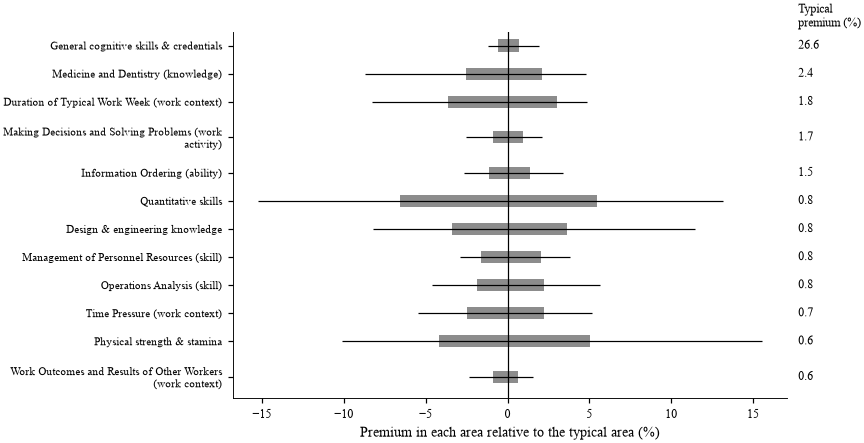

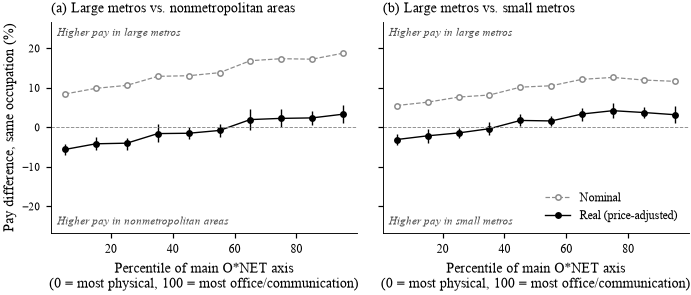

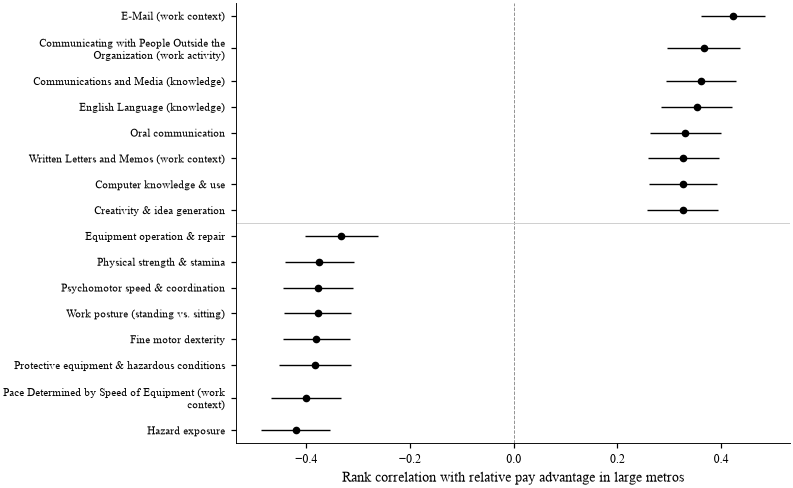

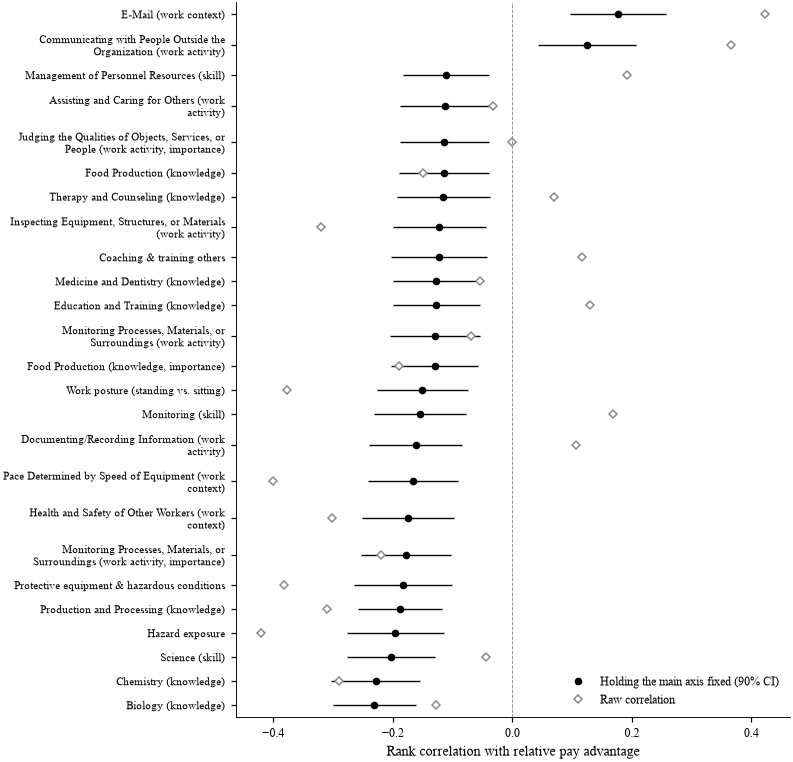

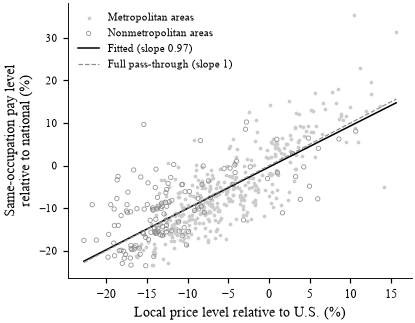

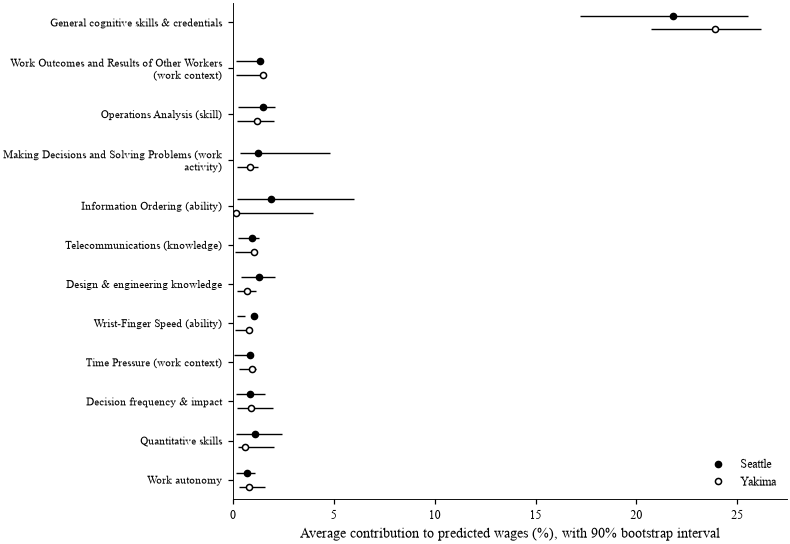

In [13]:
serif_pref = ["Times New Roman", "Liberation Serif", "Nimbus Roman", "TeX Gyre Termes", "CMU Serif", "DejaVu Serif"]
ttf = {f.name for f in font_manager.fontManager.ttflist if f.fname.lower().endswith(".ttf")}
plt.rcParams.update({
    "font.family": "serif", "font.serif": [next((f for f in serif_pref if f in ttf), "DejaVu Serif")] + serif_pref,
    "mathtext.fontset": "cm", "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 9, "xtick.labelsize": 8,
    "ytick.labelsize": 7.5, "legend.fontsize": 8, "legend.frameon": False, "axes.spines.top": False,
    "axes.spines.right": False, "axes.linewidth": 0.6, "lines.linewidth": 1.0, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03, "pdf.fonttype": 42, "ps.fonttype": 42, "figure.dpi": 110})
BLACK, DARK, MID, LIGHT = "0.0", "0.3", "0.55", "0.8"
TEXTWIDTH = 6.5
GROUP_TEXT = {"Large metros": "large metros", "Small metros": "small metros", "Nonmetro (rural)": "nonmetropolitan areas"}
wrapl = lambda s, w=50: "\n".join(textwrap.wrap(str(s), w))

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf")
    plt.show(); plt.close(fig)

LINE_IN, ROW_PAD_IN, MARGIN_IN = 0.135, 0.12, 0.85      
def rows(labels, width=50, pad=ROW_PAD_IN):
    wrapped = [wrapl(l, width) for l in labels]
    h = np.array([LINE_IN * (w.count("\n") + 1) + pad for w in wrapped])
    return wrapped, -(np.cumsum(h) - h / 2), h.sum()

def row_axes(total, extra=0.0):
    fig, ax = plt.subplots(figsize=(TEXTWIDTH, total + MARGIN_IN + extra))
    ax.set_ylim(-total, 0)
    return fig, ax

def dotplot(ax, y, pt_, lo, hi, filled=True, label=None, marker="o"):
    ax.hlines(y, lo, hi, color=BLACK, lw=0.9)
    ax.plot(pt_, y, marker, ms=4, color=BLACK, markerfacecolor=BLACK if filled else "white", label=label, linestyle="none")

def direction_labels(ax, top, bottom):
    ax.text(0.02, 0.97, top, transform=ax.transAxes, fontsize=7, style="italic", va="top", color=DARK)
    ax.text(0.02, 0.03, bottom, transform=ax.transAxes, fontsize=7, style="italic", va="bottom", color=DARK)

def binned(x, yv, w, n=N_BINS, seed=0):
    ok = yv.notna()
    x, yv, w = x[ok], yv[ok], w[ok]
    b = pd.qcut(x.rank(method="first"), n, labels=False)
    rng = np.random.default_rng(seed)
    out = []
    for k in range(n):
        m = (b == k).values
        xs, ys, ws = x.values[m], yv.values[m], w.values[m]
        bs = [np.average(ys[i], weights=ws[i]) for i in (rng.integers(0, m.sum(), m.sum()) for _ in range(1000))]
        out.append((xs.mean(), np.average(ys, weights=ws), np.percentile(bs, 5), np.percentile(bs, 95)))
    return np.array(out)

# Figure 1: premium variation across markets
lab, y, total = rows([pretty(g) for g in tg], width=46)
fig, ax = row_axes(total, extra=0.15)
ax.hlines(y, rel_.quantile(0.05), rel_.quantile(0.95), color=BLACK, lw=0.8)
ax.barh(y, rel_.quantile(0.75) - rel_.quantile(0.25), left=rel_.quantile(0.25), height=0.11, color=MID)
ax.axvline(0, color=BLACK, lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(lab)
for yy, g in zip(y, tg):
    ax.text(1.02, yy, f"{typical0[g]:.1f}", transform=ax.get_yaxis_transform(), va="center", fontsize=8)
ax.text(1.02, 0.01, "Typical\npremium (%)", transform=ax.get_yaxis_transform(), fontsize=8, va="bottom", clip_on=False)
ax.set_xlabel("Premium in each area relative to the typical area (%)")
save(fig, "fig2_premium_variation")

# Figure 2: nominal and real same-occupation pay along the axis
fig, axes = plt.subplots(1, 2, figsize=(TEXTWIDTH, 2.9), sharey=True)
allb = {}
for a, b in PAIRS:
    allb[(a, b, "real")] = binned(axis_pct0, rp0[f"real: {a} vs. {b}"], w0)
    allb[(a, b, "nominal")] = binned(axis_pct0, rp0[f"nominal: {a} vs. {b}"], w0)
ylim6 = np.abs(np.concatenate([np.r_[v[:, 2], v[:, 3]] for v in allb.values()])).max() * 1.25
for k, (ax, (a, b)) in enumerate(zip(axes, PAIRS)):
    nb_, rb_ = allb[(a, b, "nominal")], allb[(a, b, "real")]
    ax.plot(nb_[:, 0], nb_[:, 1], "o--", color=MID, ms=3.5, lw=0.8, markerfacecolor="white", label="Nominal")
    ax.vlines(rb_[:, 0], rb_[:, 2], rb_[:, 3], color=BLACK, lw=0.9)
    ax.plot(rb_[:, 0], rb_[:, 1], "o-", color=BLACK, ms=3.5, lw=0.9, label="Real (price-adjusted)")
    ax.axhline(0, color=MID, lw=0.6, ls="--"); ax.set_ylim(-ylim6, ylim6)
    ax.set_title(f"({'ab'[k]}) {GROUP_TEXT[a].capitalize()} vs. {GROUP_TEXT[b]}", loc="left")
    direction_labels(ax, f"Higher pay in {GROUP_TEXT[a]}", f"Higher pay in {GROUP_TEXT[b]}")
    ax.set_xlabel("Percentile of main O*NET axis\n(0 = most physical, 100 = most office/communication)")
axes[0].set_ylabel("Pay difference, same occupation (%)"); axes[1].legend(loc="lower right")
fig.tight_layout(w_pad=1.5)
save(fig, "fig6_real_pay")

# Figure 3: model free, strongest in each direction 
sigr = mf0[mf0["q_raw"] < FDR].sort_values("raw")
pos, neg = sigr[sigr["raw"] > 0].tail(8).iloc[::-1], sigr[sigr["raw"] < 0].head(8).iloc[::-1]
show = pd.concat([pos, neg])
lab, y, total = rows([pretty(g) for g in show.index], width=46)
fig, ax = row_axes(total)
dotplot(ax, y, show["raw"], show["raw"] - 1.645 * show["raw_se"], show["raw"] + 1.645 * show["raw_se"])
ax.axvline(0, color=MID, lw=0.6, ls="--")
if len(pos) and len(neg):
    ax.axhline((y[len(pos) - 1] + y[len(pos)]) / 2, color=LIGHT, lw=0.6)
ax.set_yticks(y); ax.set_yticklabels(lab)
ax.set_xlabel("Rank correlation with relative pay advantage in large metros")
save(fig, "fig4_modelfree")

# Figure 4: beyond the axis
sp = mf0[mf0["q_partial"] < FDR].sort_values("partial", ascending=False)
lab, y, total = rows([pretty(g) for g in sp.index], width=46)
fig, ax = row_axes(total)
dotplot(ax, y, sp["partial"], sp["partial"] - 1.645 * sp["partial_se"], sp["partial"] + 1.645 * sp["partial_se"],
        label="Holding the main axis fixed (90% CI)")
ax.plot(sp["raw"], y, "D", ms=4, markerfacecolor="white", markeredgecolor=MID, linestyle="none", label="Raw correlation")
ax.axvline(0, color=MID, lw=0.6, ls="--")
ax.set_yticks(y); ax.set_yticklabels(lab)
ax.set_xlabel("Rank correlation with relative pay advantage"); ax.legend(loc="lower right")
save(fig, "fig5_residual_skills")

# Figure 5: price pass-through
x_, y_ = to_pct(lv0["log_price"]), to_pct(lv0["level"])
nm_ = lv0["area_type"].eq("nonmetro")
fig, ax = plt.subplots(figsize=(TEXTWIDTH * 0.62, TEXTWIDTH * 0.5))
ax.scatter(x_[~nm_], y_[~nm_], s=6, color=LIGHT, linewidths=0, label="Metropolitan areas")
ax.scatter(x_[nm_], y_[nm_], s=8, facecolors="none", edgecolors=MID, linewidths=0.5, label="Nonmetropolitan areas")
xs_ = np.linspace(lv0["log_price"].min(), lv0["log_price"].max(), 50)
ax.plot(to_pct(xs_), to_pct(beta[0] + beta[1] * xs_), color=BLACK, lw=1, label=f"Fitted (slope {pt['slope']:.2f})")
ax.plot(to_pct(xs_), to_pct(xs_), "--", color=MID, lw=0.8, label="Full pass-through (slope 1)")
ax.set_xlabel("Local price level relative to U.S. (%)"); ax.set_ylabel("Same-occupation pay level\nrelative to national (%)")
ax.legend(loc="upper left", fontsize=7)
save(fig, "figA4_price_passthrough")

# Figure A1: Seattle vs. Yakima 
if case is not None:
    tc = case["point"].mean(axis=1).nlargest(12).index
    lab, y, total = rows([pretty(g) for g in tc], width=46, pad=ROW_PAD_IN + 0.14)
    fig, ax = row_axes(total)
    for j, (a, nm) in enumerate(case["names"].items()):
        dotplot(ax, y + (0.07 if j == 0 else -0.07), case["point"].loc[tc, a], case["lo"].loc[tc, a], case["hi"].loc[tc, a],
                filled=(j == 0), label=nm)
    ax.set_yticks(y); ax.set_yticklabels(lab)
    ax.set_xlabel("Average contribution to predicted wages (%), with 90% bootstrap interval"); ax.set_xlim(left=0)
    ax.legend(loc="lower right")
    save(fig, "figA3_case_study")

## 12. Numbers quoted in the text

In [14]:
summary = pd.Series({
    "O*NET ratings": X_all.shape[1],
    "Occupations matched to O*NET": X_all.shape[0],
    "Share of national employment matched (%)": round(coverage["employment_share"].iloc[:3].sum(), 1),
    "Areas (metro/nonmetro)": f"{int(area_info.loc[areas0, 'area_type'].eq('msa').sum())} / "
                                f"{int(area_info.loc[areas0, 'area_type'].eq('nonmetro').sum())}",
    "Occupation-by-area cells": f"{len(d0):,}",
    "Occupations reported only as annual salaries": n_annual,
    "National model R^2: XGBoost/ridge": f"{r2_nat['xgboost']:.2f} / {r2_nat['ridge']:.2f}",
    "Skills and skill groups": len(groups),
    "Groups combining different measures": len(gt_),
    "Measures with level and importance combined only with each other": n_pair,
    "Ratings standing alone": n_alone,
    "Average within-group correlation (range)": f"{gt_['mean_abs_rho'].min():.2f} to {gt_['mean_abs_rho'].max():.2f}",
    "Rent calibration: cross-validated R^2": round(r2_rent, 2),
    "Nonmetro price estimate vs. U.S. (%)": round(to_pct(np.log(implied_us)), 1),
    "BEA published U.S. nonmetro level vs. U.S. (%)": round(to_pct(np.log(us_nonmetro)), 1) if us_nonmetro else "--",
    "States bounded at 80% or 100% of state level": n_bounded,
    "Core test gain (90% CI)": f"{core_rel['mean']:.3f} ({core_rel['lo']:.3f} to {core_rel['hi']:.3f})",
    "Core test p-value/held-out samples improved": f"{core_rel['p']:.3f} / {core_rel['positive']} of {core_rel['n']}",
    "Rank agreement with typical area, median": round(rho0.median(), 2),
    "Largest premium: typical (%)": f"{pretty(tg[0])}: {typical0[tg[0]]:.1f}",
    "Largest premium: 5th to 95th pct. of areas vs. typical (%)": f"{rel_[tg[0]].quantile(0.05):.1f} to {rel_[tg[0]].quantile(0.95):.1f}",
    "Areas: large/small metros/nonmetro": " / ".join(str(int(cmp0["n_areas"].get(k, 0))) for k in ["Large metros", "Small metros", "Nonmetro (rural)"]),
    "Common occupations in comparisons": len(cmp0["common"]),
    "Main axis variance share (%)": round(cmp0["axis_var"] * 100),
    "Significant skills: raw/holding the axis fixed": f"{int((mf0['q_raw'] < FDR).sum())} / {int((mf0['q_partial'] < FDR).sum())} of {len(mf0)}",
    "Pass-through (90% CI)": f"{pt['slope']:.2f} ({pt['lo']:.2f} to {pt['hi']:.2f})",
    "Pass-through R^2": round(pt["r2"], 2),
    "Same occupation, nominal/real difference (%)": f"{wavg(rp0[f'nominal: {ga} vs. {gb}'], w0):.1f} / {wavg(rp0[f'real: {ga} vs. {gb}'], w0):.1f}",
    "Most physical tenth, nominal/real (%)": f"{tt0['nominal'].iloc[0]:.1f} / {tt0['real'].iloc[0]:.1f}",
    "Most office-based tenth, nominal/real (%)": f"{tt0['nominal'].iloc[-1]:.1f} / {tt0['real'].iloc[-1]:.1f}",
    "Most physical tenth: real advantage in nonmetro (%)": round(to_pct(-np.log1p(tt0["real"].iloc[0] / 100)), 1),
    "Office minus physical across price assumptions (pts)": f"{sens['Office minus physical (pts)'].min():.1f} to {sens['Office minus physical (pts)'].max():.1f}",
    "Seattle vs. Yakima: common occupations": case["n"] if case else "--",
    "Run time (minutes)": round((time.time() - T0) / 60),
}, name="value")
if QUICK_RUN:
    print("QUICK_RUN: these numbers are for checking only and will not match the paper.")
display(summary.to_frame())

,value
O*NET ratings,380
Occupations matched to O*NET,762
Share of national employment matched (%),96.3
Areas (metro / nonmetro),387 / 134
Occupation-by-area cells,"172,520"
Occupations reported only as annual salaries,55
National model R^2: XGBoost / ridge,0.81 / 0.78
Skills and skill groups,156
Groups combining different measures,28
Measures with level and importance combined only with each other,74


## 13. Does industry mix explain the results?

OEWS publishes industry detail only for the nation, so this check uses each occupation's national industry mix
from the same OEWS file: its employment shares in physical industries (agriculture, mining, and utilities;
construction; manufacturing; transportation), in education and health care, and in the public sector.

This is to test with industries controlled to see if the results still hold.

This test cannot show the same occupation being in different industries in different places.

In [16]:
# Each occupation's national industry mix (OEWS national industry and ownership estimates)
nat_rows = raw[raw["AREA_TYPE"].astype(str).str.strip().eq("1")].copy()
nat_rows["soc"] = nat_rows["OCC_CODE"].astype(str).str.strip()
nat_rows["emp"] = _num(nat_rows["TOT_EMP"])
ig = nat_rows["I_GROUP"].astype(str).str.lower().str.strip()
own = nat_rows["OWN_CODE"].astype(str).str.strip()
print("National rows by industry level:", ig.value_counts().to_dict())

INDUSTRIES = {"Agriculture, mining & utilities": ["11", "21", "22"], "Construction": ["23"],
              "Manufacturing": ["31", "32", "33"], "Transportation & warehousing": ["48", "49"],
              "Education": ["61"], "Health care": ["62"]}
sec = nat_rows[ig.eq("sector")].copy()
sec["sec2"] = sec["NAICS"].astype(str).str.replace(r"\D", "", regex=True).str[:2]
sec = sec.sort_values("emp", ascending=False).drop_duplicates(["sec2", "soc"])      # broadest ownership row per sector
total = nat["tot_emp"]
ind = pd.DataFrame(index=total.index)
for name, codes in INDUSTRIES.items():
    ind[name] = sec[sec["sec2"].isin(codes)].groupby("soc")["emp"].sum().reindex(total.index).fillna(0) / total
pub = nat_rows[ig.str.startswith("cross-industry") & own.isin(["1", "2", "3"])].groupby("soc")["emp"].sum()   # federal, state, local
if len(pub):
    ind["Public sector"] = pub.reindex(total.index).fillna(0) / total
else:
    print("No ownership rows found; public-sector share left out.")
ind = ind.clip(0, 1)
covered = sec.groupby("soc")["emp"].sum().reindex(total.index) / total
print(f"Sector detail found for {sec['soc'].nunique()} occupations; median share of an occupation's employment "
      f"in a published sector cell: {covered.median():.0%} (the rest is suppressed or in unlisted sectors)")

occs = cmp0["common"]
IND = ind.loc[occs]
display(IND.describe().loc[["mean", "50%", "max"]].round(2))

# The physical-to-office gap, with and without industry mix held fixed
def gap_fit(yv, controls):
    ok = yv.notna()
    Xr = np.column_stack([np.ones(ok.sum()), axis_pct0[ok]] + ([controls[ok].values] if controls is not None else []))
    w = w0[ok].values
    b = np.linalg.lstsq(Xr * np.sqrt(w)[:, None], yv[ok].values * np.sqrt(w), rcond=None)[0]
    return b[1] * 90, b                                             

rows_ = {}
for lab, yv in [("Real pay difference (%)", rp0[f"real: {ga} vs. {gb}"]),
                ("Relative pay advantage (%)", to_pct(cmp0["dv"]))]:
    g_raw, _ = gap_fit(yv, None)
    g_ind, b_ind = gap_fit(yv, IND)
    rows_[lab] = {"Office minus physical (pts)": round(g_raw, 1), "Holding industry mix fixed (pts)": round(g_ind, 1),
                  "Share remaining": f"{g_ind / g_raw:.0%}"}
    if lab.startswith("Real"):
        coefs = pd.Series(b_ind[2:], index=IND.columns)
print(f"Physical-to-office gap, {ga} vs. {gb} (linear fit along the axis)")
display(pd.DataFrame(rows_).T)
print("Industry coefficients in the real-pay fit: points of pay difference if all of an occupation's employment "
      "were in that industry (negative = relatively better paid outside large metros)")
display(coefs.round(1).to_frame("coefficient"))

# Skills beyond the axis, also holding industry mix fixed
def modelfree_controls(C, dv, A, w, n_boot, seed=RANDOM_STATE):
    def stat(idx):
        Cr, dr = stats.rankdata(C.values[idx], axis=0), stats.rankdata(dv.values[idx])
        Ar = np.column_stack([np.ones(len(idx)), stats.rankdata(A.values[idx], axis=0)])
        ww = w[idx]; sw = np.sqrt(ww)[:, None]
        resid = lambda v: v - Ar @ np.linalg.lstsq(Ar * sw, v * sw, rcond=None)[0]
        return wcorr(resid(Cr), resid(dr[:, None])[:, 0], ww)
    part = stat(np.arange(len(dv)))
    rng = np.random.default_rng(seed)
    se = np.std([stat(rng.integers(0, len(dv), len(dv))) for _ in range(n_boot)], axis=0)
    return pd.DataFrame({"partial": part, "q": bh(2 * stats.norm.sf(np.abs(part / se)))}, index=C.columns)

C0 = composites(X_all, groups, occs)
mf_ind = modelfree_controls(C0, cmp0["dv"], pd.concat([cmp0["axis"].loc[occs].rename("axis"), IND], axis=1),
                            w0.values, N_BOOT_COMPARE)
left = mf0.index[mf0["q_partial"] < FDR]
check = pd.DataFrame({"Axis only": mf0.loc[left, "partial"].round(2),
                      "Axis + industry mix": mf_ind.loc[left, "partial"].round(2),
                      "Still significant": mf_ind.loc[left, "q"] < FDR}).rename(index=pretty)
check = check.sort_values("Axis only")
print(f"Skills significant beyond the axis: {len(left)}; still significant with industry mix also held fixed: "
      f"{int(check['Still significant'].sum())}. All skills significant with both controls: "
      f"{int((mf_ind['q'] < FDR).sum())} of {len(mf_ind)}")
display(check)

National rows by industry level: {'4-digit': 83271, '3-digit': 38789, 'sector': 16386, '5-digit': 15468, '4-digit, ownership': 10037, 'cross-industry, ownership': 5654, '3-digit, ownership': 4565, '6-digit': 1836, 'cross-industry': 1401}
Sector detail found for 1394 occupations; median share of an occupation's employment in a published sector cell: 100% (the rest is suppressed or in unlisted sectors)


,"Agriculture, mining & utilities",Construction,Manufacturing,Transportation & warehousing,Education,Health care,Public sector
mean,0.03,0.06,0.13,0.04,0.11,0.14,0.19
50%,0.00,0.00,0.01,0.00,0.01,0.00,0.06
max,0.97,0.98,0.97,1.00,1.00,0.98,1.00


Physical-to-office gap, Large metros vs. Nonmetro (rural) (linear fit along the axis)


,Office minus physical (pts),Holding industry mix fixed (pts),Share remaining
Real pay difference (%),9.3,7.1,77%
Relative pay advantage (%),9.7,7.6,78%


Industry coefficients in the real-pay fit: points of pay difference if all of an occupation's employment were in that industry (negative = relatively better paid outside large metros)


,coefficient
"Agriculture, mining & utilities",-7.7
Construction,2.0
Manufacturing,-10.0
Transportation & warehousing,-9.1
Education,-6.9
Health care,-7.7
Public sector,6.2


Skills significant beyond the axis: 25; still significant with industry mix also held fixed: 18. All skills significant with both controls: 28 of 156


,Axis only,Axis + industry mix,Still significant
Chemistry (knowledge),-0.23,-0.20,True
Biology (knowledge),-0.23,-0.24,True
Hazard exposure,-0.20,-0.22,True
Science (skill),-0.20,-0.17,True
Production and Processing (knowledge),-0.19,-0.14,True
Protective equipment & hazardous conditions,-0.18,-0.16,True
"Monitoring Processes, Materials, or Surroundings (work activity, importance)",-0.18,-0.13,True
Health and Safety of Other Workers (work context),-0.18,-0.17,True
Pace Determined by Speed of Equipment (work context),-0.17,-0.11,False
Documenting/Recording Information (work activity),-0.16,-0.14,True
